<a href="https://colab.research.google.com/github/iam-vsr/olist/blob/main/olist_analysis_simple.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Olist E-Commerce Analysis — What Drives Customer Satisfaction?

**Dataset:** Brazilian E-Commerce Public Dataset by Olist — ~100k orders placed between Sep 2016 and Oct 2018 (Kaggle).
**Tools:** Python · pandas · matplotlib · seaborn

### Business problem
Olist connects small Brazilian sellers to large online marketplaces. Leadership wants to know:
how the marketplace has performed, what makes customers happy or unhappy, and what to fix first.

### Questions answered
1. **Performance over time** — how did orders, revenue and review scores trend?
2. **Delivery vs. satisfaction** — do late deliveries lead to worse reviews? Everywhere, or only in some places?
3. **Sellers & geography** — how does location affect delivery time, freight cost and reviews?
4. **Product categories** — which categories are stronger or weaker than average?
5. **Payments** — how do payment type and instalments relate to order value and satisfaction?
6. **Root cause** — what are the main reasons behind low (1–2 star) reviews?

### Approach
Load 8 CSV files → check data quality → clean → join everything into **one row per order** → answer each question with group-by summaries and simple charts → export a **PDF report**.

> **Key metric definitions**
> - **Order value** = item prices + freight for that order
> - **Late delivery** = delivered *after* the estimated delivery date shown to the customer
> - **Bad review** = 1 or 2 stars

## 1. Setup

In [ ]:
import os
import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titleweight"] = "bold"
pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", 30)

GREEN, RED, BLUE, GREY = "#2a9d8f", "#e76f51", "#264653", "#adb5bd"

## 2. Load the data from Google Drive
The nine CSV files are stored in a Google Drive folder. We use eight of them — the geolocation table
(1M rows of latitude/longitude) is not needed because we analyse geography at the **state** level.

In [ ]:
# Mount Google Drive (only works inside Google Colab)
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    print("Not running in Colab - make sure DATA_DIR below points to your data folder.")

DATA_DIR = "/content/drive/MyDrive/OLIST/"   # <-- folder that contains the CSV files

orders      = pd.read_csv(DATA_DIR + "olist_orders_dataset.csv")
items       = pd.read_csv(DATA_DIR + "olist_order_items_dataset.csv")
payments    = pd.read_csv(DATA_DIR + "olist_order_payments_dataset.csv")
reviews     = pd.read_csv(DATA_DIR + "olist_order_reviews_dataset.csv")
customers   = pd.read_csv(DATA_DIR + "olist_customers_dataset.csv")
products    = pd.read_csv(DATA_DIR + "olist_products_dataset.csv")
sellers     = pd.read_csv(DATA_DIR + "olist_sellers_dataset.csv")
translation = pd.read_csv(DATA_DIR + "product_category_name_translation.csv", encoding="utf-8-sig")

print("All files loaded.")

Mounted at /content/drive
All files loaded.


In [ ]:
# Folder where charts and the final PDF report will be saved (inside the same Drive folder)
REPORT_DIR = os.path.join(DATA_DIR, "report")
os.makedirs(REPORT_DIR, exist_ok=True)

report_charts = []   # every chart we want in the final PDF is added here
summary = {}         # headline numbers used in the final report

def save_chart(fig, name, title, caption):
    # Save a chart as PNG and remember it for the PDF report.
    path = os.path.join(REPORT_DIR, name + ".png")
    fig.savefig(path, dpi=150, bbox_inches="tight")
    report_charts.append({"path": path, "title": title, "caption": caption})

## 3. Data understanding
Before cleaning, check the size of each table, missing values and duplicates.

In [ ]:
tables = {"orders": orders, "items": items, "payments": payments, "reviews": reviews,
          "customers": customers, "products": products, "sellers": sellers,
          "translation": translation}

overview = pd.DataFrame({
    name: {"rows": len(t), "columns": t.shape[1],
           "missing values": int(t.isna().sum().sum()),
           "duplicate rows": int(t.duplicated().sum())}
    for name, t in tables.items()
}).T
overview

,rows,columns,missing values,duplicate rows
orders,99441,8,4908,0
items,112650,6,0,0
payments,103886,5,0,0
reviews,100000,7,146532,0
customers,99441,5,0,0
products,32951,9,2448,0
sellers,3095,4,0,0
translation,71,2,0,0


In [ ]:
print("Order status counts:")
print(orders["order_status"].value_counts(), "\n")

print("Missing values in the orders table:")
print(orders.isna().sum(), "\n")

print("Unique customer_id       :", customers["customer_id"].nunique())
print("Unique customer_unique_id:", customers["customer_unique_id"].nunique())
print("Orders with more than one review:", reviews["order_id"].duplicated().sum())

Order status counts:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64 

Missing values in the orders table:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64 

Unique customer_id       : 99441
Unique customer_unique_id: 96096
Orders with more than one review: 559


**What we learned**
- About 97% of orders are *delivered*. Other statuses (canceled, shipped, unavailable…) have no delivery date, which explains most missing timestamps.
- `customer_id` is unique **per order**, while `customer_unique_id` identifies the **person** — so real customers are fewer than orders.
- An order can have several items, several payment records and (rarely) more than one review, so tables must be **aggregated to one row per order** before joining. Otherwise rows get duplicated and totals become wrong.
- ~610 products have no category name.

## 4. Data cleaning
| Issue | Fix |
|---|---|
| Dates stored as text | Convert to datetime |
| Some orders have 2+ reviews | Keep the most recent review per order |
| Category names in Portuguese | Translate to English using the translation table |
| Missing category | Label as `unknown` (kept, not dropped — it may matter) |
| Non-delivered orders have no delivery date | Kept in the data, but excluded from delivery-time calculations |

In [ ]:
# 1. Convert date columns
date_cols = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
             "order_delivered_customer_date", "order_estimated_delivery_date"]
for col in date_cols:
    orders[col] = pd.to_datetime(orders[col])
reviews["review_answer_timestamp"] = pd.to_datetime(reviews["review_answer_timestamp"])

# 2. One review per order (keep the latest one)
reviews = (reviews.sort_values("review_answer_timestamp")
                  .drop_duplicates(subset="order_id", keep="last"))

# 3. English category names; missing -> "unknown"
products = products.merge(translation, on="product_category_name", how="left")
products["category"] = (products["product_category_name_english"]
                        .fillna(products["product_category_name"])   # 2 categories have no translation
                        .fillna("unknown"))

print("Reviews after removing duplicates:", len(reviews))
print("Products with unknown category  :", (products["category"] == "unknown").sum())

Reviews after removing duplicates: 99441
Products with unknown category  : 610


## 5. Build one table with one row per order
Items and payments have several rows per order, so we **summarise them per order first** and then join
everything onto the orders table.

In [ ]:
# --- Items: one row per order ---
items_full = (items.merge(products[["product_id", "category"]], on="product_id", how="left")
                   .merge(sellers[["seller_id", "seller_state"]], on="seller_id", how="left")
                   .sort_values(["order_id", "order_item_id"]))

items_per_order = items_full.groupby("order_id").agg(
    n_items      = ("order_item_id", "count"),
    n_sellers    = ("seller_id", "nunique"),
    product_value= ("price", "sum"),
    freight_value= ("freight_value", "sum"),
    category     = ("category", "first"),       # category of the first item
    seller_state = ("seller_state", "first"),   # state of the first item's seller
).reset_index()

# --- Payments: one row per order ---
payments_per_order = (payments.sort_values(["order_id", "payment_sequential"])
                              .groupby("order_id").agg(
    payment_type   = ("payment_type", "first"),         # main (first) payment method
    installments   = ("payment_installments", "max"),
    payment_value  = ("payment_value", "sum"),
)).reset_index()

# --- Join everything onto orders ---
df = (orders
      .merge(customers[["customer_id", "customer_unique_id", "customer_state"]], on="customer_id", how="left")
      .merge(items_per_order, on="order_id", how="left")
      .merge(payments_per_order, on="order_id", how="left")
      .merge(reviews[["order_id", "review_score"]], on="order_id", how="left"))

print("Orders in raw table :", len(orders))
print("Rows in final table :", len(df), "(should be the same -> no duplication)")

Orders in raw table : 99441
Rows in final table : 99441 (should be the same -> no duplication)


In [ ]:
# --- New columns (feature engineering) ---
df["order_value"]    = df["product_value"] + df["freight_value"]
df["purchase_month"] = df["order_purchase_timestamp"].dt.to_period("M").dt.to_timestamp()

# Delivery features (only meaningful for delivered orders)
df["was_delivered"]  = (df["order_status"] == "delivered") & df["order_delivered_customer_date"].notna()
df["delivery_days"]  = (df["order_delivered_customer_date"] - df["order_purchase_timestamp"]).dt.days
df["days_late"]      = (df["order_delivered_customer_date"].dt.normalize()
                        - df["order_estimated_delivery_date"]).dt.days      # > 0 means late
df["is_late"]        = df["was_delivered"] & (df["days_late"] > 0)

df["delivery_status"] = pd.cut(df["days_late"], bins=[-1000, 0, 3, 7, 1000],
                               labels=["On time / early", "1-3 days late", "4-7 days late", "8+ days late"])
df.loc[~df["was_delivered"], "delivery_status"] = np.nan

# Review flag: 1 = bad review (1-2 stars), 0 = otherwise, NaN = no review
df["bad_review"] = np.where(df["review_score"].isna(), np.nan, (df["review_score"] <= 2).astype(float))

# Geography: Brazil's 27 states grouped into 5 regions + same-state shipping flag
REGIONS = {
    "North":        ["AC", "AP", "AM", "PA", "RO", "RR", "TO"],
    "Northeast":    ["AL", "BA", "CE", "MA", "PB", "PE", "PI", "RN", "SE"],
    "Central-West": ["DF", "GO", "MT", "MS"],
    "Southeast":    ["ES", "MG", "RJ", "SP"],
    "South":        ["PR", "RS", "SC"],
}
state_to_region = {s: r for r, states in REGIONS.items() for s in states}
df["customer_region"] = df["customer_state"].map(state_to_region)
df["same_state"]      = df["seller_state"] == df["customer_state"]

df[["order_id", "order_status", "order_value", "delivery_days", "days_late",
    "delivery_status", "review_score", "category", "payment_type", "customer_region"]].head()

,order_id,order_status,order_value,delivery_days,days_late,delivery_status,review_score,category,payment_type,customer_region
0,e481f51cbdc54678b7cc49136f2d6af7,delivered,38.71,8.00,-8.00,On time / early,4,housewares,credit_card,Southeast
1,53cdb2fc8bc7dce0b6741e2150273451,delivered,141.46,13.00,-6.00,On time / early,4,perfumery,boleto,Northeast
2,47770eb9100c2d0c44946d9cf07ec65d,delivered,179.12,9.00,-18.00,On time / early,5,auto,credit_card,Central-West
3,949d5b44dbf5de918fe9c16f97b45f8a,delivered,72.20,13.00,-13.00,On time / early,5,pet_shop,credit_card,Northeast
4,ad21c59c0840e6cb83a9ceb5573f8159,delivered,28.62,2.00,-10.00,On time / early,5,stationery,credit_card,Southeast


## 6. Quick overview (key KPIs)

In [ ]:
valid     = df[~df["order_status"].isin(["canceled", "unavailable"])]   # orders that went through
delivered = df[df["was_delivered"]]

summary["Total orders"]          = f"{len(df):,}"
summary["Unique customers"]      = f"{df['customer_unique_id'].nunique():,}"
summary["Total revenue"]         = f"R$ {valid['order_value'].sum()/1e6:,.1f}M"
summary["Avg order value"]       = f"R$ {valid['order_value'].mean():,.0f}"
summary["Avg review score"]      = f"{df['review_score'].mean():.2f} / 5"
summary["Bad reviews (1-2 star)"]= f"{df['bad_review'].mean()*100:.1f}%"
summary["Late deliveries"]       = f"{delivered['is_late'].mean()*100:.1f}%"
summary["Avg delivery time"]     = f"{delivered['delivery_days'].mean():.1f} days"

for k, v in summary.items():
    print(f"{k:<24}: {v}")

Total orders            : 99,441
Unique customers        : 96,096
Total revenue           : R$ 15.7M
Avg order value         : R$ 160
Avg review score        : 4.07 / 5
Bad reviews (1-2 star)  : 15.1%
Late deliveries         : 6.8%
Avg delivery time       : 12.1 days


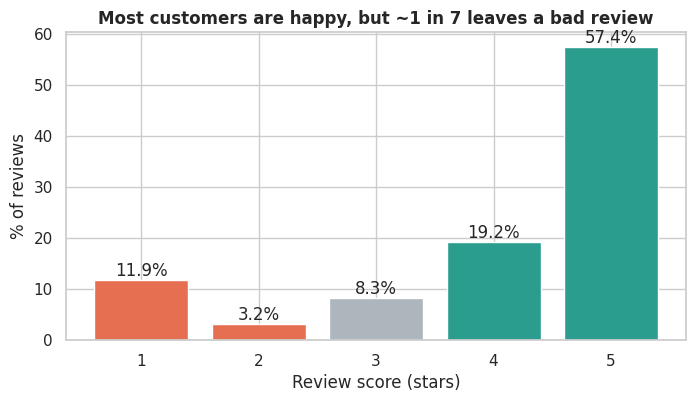

In [ ]:
score_share = df["review_score"].value_counts(normalize=True).sort_index() * 100

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(score_share.index.astype(int).astype(str), score_share.values,
              color=[RED, RED, GREY, GREEN, GREEN])
ax.bar_label(bars, fmt="%.1f%%")
ax.set_title("Most customers are happy, but ~1 in 7 leaves a bad review")
ax.set_xlabel("Review score (stars)")
ax.set_ylabel("% of reviews")
plt.show()

save_chart(fig, "0_review_distribution", "Review score distribution",
           f"{score_share.loc[5]:.0f}% of reviews are 5 stars, while "
           f"{score_share.loc[[1, 2]].sum():.0f}% are 1-2 stars. The rest of this analysis explains "
           f"what separates those two groups.")

## 7. Q1 — How has the marketplace performed over time?
We use **Jan 2017 – Aug 2018** (the months with complete data; late 2016 and Sep–Oct 2018 have very few orders).
Canceled and unavailable orders are excluded.

In [ ]:
period = valid[(valid["purchase_month"] >= "2017-01-01") & (valid["purchase_month"] <= "2018-08-01")]

monthly = period.groupby("purchase_month").agg(
    orders     = ("order_id", "count"),
    revenue    = ("order_value", "sum"),
    avg_review = ("review_score", "mean"),
)
monthly["avg_order_value"] = monthly["revenue"] / monthly["orders"]
monthly["late_pct"] = period[period["was_delivered"]].groupby("purchase_month")["is_late"].mean() * 100
monthly

,orders,revenue,avg_review,avg_order_value,late_pct
purchase_month,,,,,
2017-01-01,787,"136,943.46",4.08,174.01,2.93
2017-02-01,1718,"283,561.69",4.09,165.05,2.96
2017-03-01,2617,"425,617.96",4.12,162.64,4.56
2017-04-01,2377,"405,848.61",4.05,170.74,6.56
2017-05-01,3640,"582,710.83",4.16,160.09,2.99
2017-06-01,3205,"499,652.24",4.16,155.90,3.03
2017-07-01,3946,"578,753.73",4.21,146.67,2.79
2017-08-01,4272,"661,903.52",4.26,154.94,2.91
2017-09-01,4227,"717,102.72",4.21,169.65,4.39


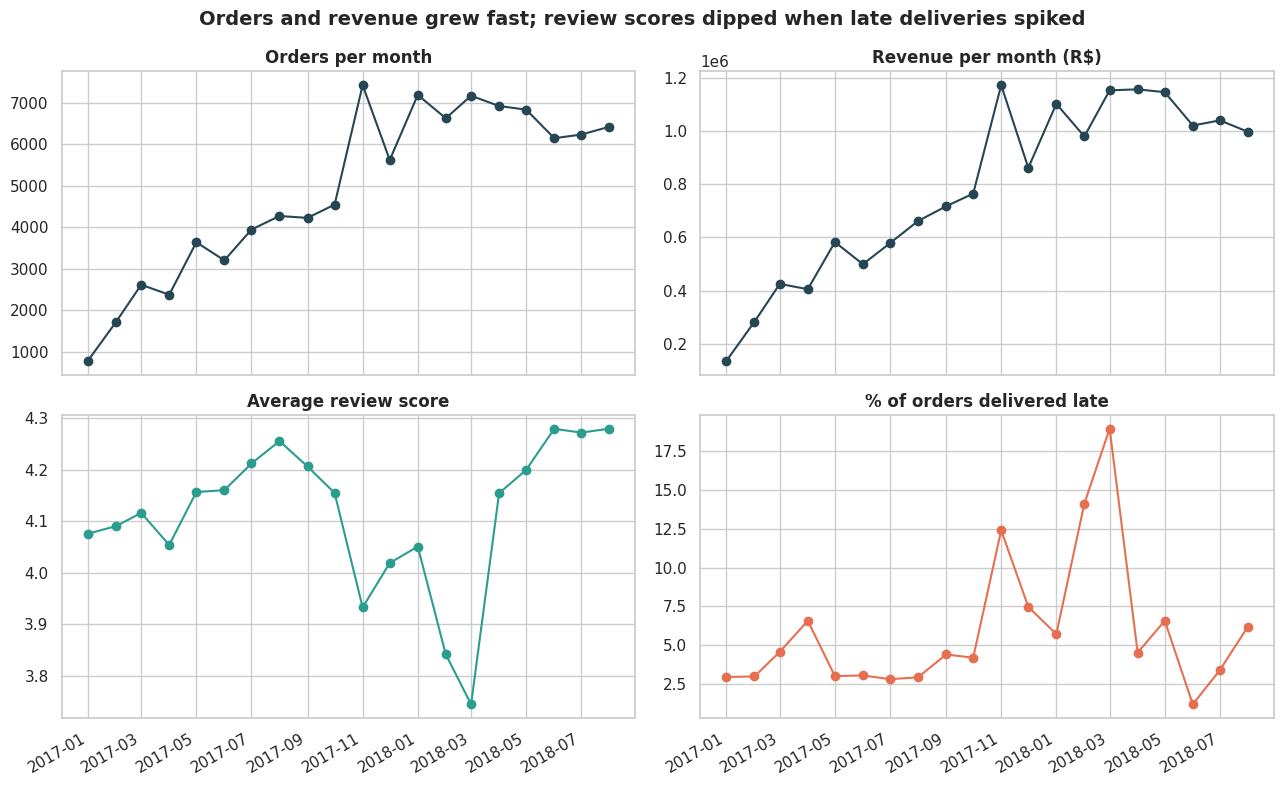

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True)
panels = [("orders", "Orders per month", BLUE),
          ("revenue", "Revenue per month (R$)", BLUE),
          ("avg_review", "Average review score", GREEN),
          ("late_pct", "% of orders delivered late", RED)]
for ax, (col, title, color) in zip(axes.flat, panels):
    ax.plot(monthly.index, monthly[col], marker="o", color=color)
    ax.set_title(title)
fig.autofmt_xdate()
fig.suptitle("Orders and revenue grew fast; review scores dipped when late deliveries spiked",
             fontsize=14, weight="bold")
plt.tight_layout()
plt.show()

In [ ]:
first, last = monthly.iloc[0], monthly.iloc[-1]
order_growth   = last["orders"] / first["orders"]
revenue_growth = last["revenue"] / first["revenue"]
aov_change     = (last["avg_order_value"] / first["avg_order_value"] - 1) * 100
worst_month    = monthly["avg_review"].idxmin()
corr_late      = monthly["late_pct"].corr(monthly["avg_review"])
corr_volume    = monthly["orders"].corr(monthly["avg_review"])

print(f"Orders grew {order_growth:.1f}x and revenue grew {revenue_growth:.1f}x (Jan 2017 -> Aug 2018).")
print(f"Average order value changed by only {aov_change:+.1f}% -> growth came from MORE orders, not bigger orders.")
print(f"Review score ranged from {monthly['avg_review'].min():.2f} to {monthly['avg_review'].max():.2f}; "
      f"worst month: {worst_month:%b %Y} ({monthly.loc[worst_month, 'late_pct']:.0f}% late deliveries).")
print(f"Correlation of monthly review score with late-delivery %: {corr_late:+.2f}")
print(f"Correlation of monthly review score with order volume   : {corr_volume:+.2f}")

summary["q1"] = (f"Orders grew {order_growth:.1f}x and revenue {revenue_growth:.1f}x from Jan 2017 to Aug 2018, "
                 f"while average order value moved only {aov_change:+.1f}% - growth came from more orders, "
                 f"not bigger baskets. Review scores moved with the late-delivery rate (correlation {corr_late:+.2f}) "
                 f"much more than with order volume (correlation {corr_volume:+.2f}).")

save_chart(fig, "1_trends_over_time", "Q1. Marketplace performance over time", summary["q1"])

Orders grew 8.2x and revenue grew 7.3x (Jan 2017 -> Aug 2018).
Average order value changed by only -10.8% -> growth came from MORE orders, not bigger orders.
Review score ranged from 3.74 to 4.28; worst month: Mar 2018 (19% late deliveries).
Correlation of monthly review score with late-delivery %: -0.87
Correlation of monthly review score with order volume   : -0.19


**Answer (Q1):** Orders and revenue rose together — growth came from *more customers ordering*, not from bigger baskets.
Review scores tell a **different story**: they did not steadily fall as volume grew, but dipped in the months where
late deliveries spiked (e.g. around Black Friday Nov 2017 and Feb–Mar 2018).

*Correlation* is a number from −1 to +1: close to −1 means "when one goes up, the other goes down".

## 8. Q2 — Does delivery timing affect review scores?
Only delivered orders that have a review are used here.

In [ ]:
rated_delivered = delivered[delivered["review_score"].notna()]

q2 = rated_delivered.groupby("delivery_status", observed=True).agg(
    orders         = ("order_id", "count"),
    avg_review     = ("review_score", "mean"),
    bad_review_pct = ("bad_review", "mean"),
)
q2["bad_review_pct"] *= 100
q2

,orders,avg_review,bad_review_pct
delivery_status,,,
On time / early,89936,4.28,9.54
1-3 days late,1870,3.28,32.41
4-7 days late,1802,2.09,68.09
8+ days late,2862,1.69,79.49


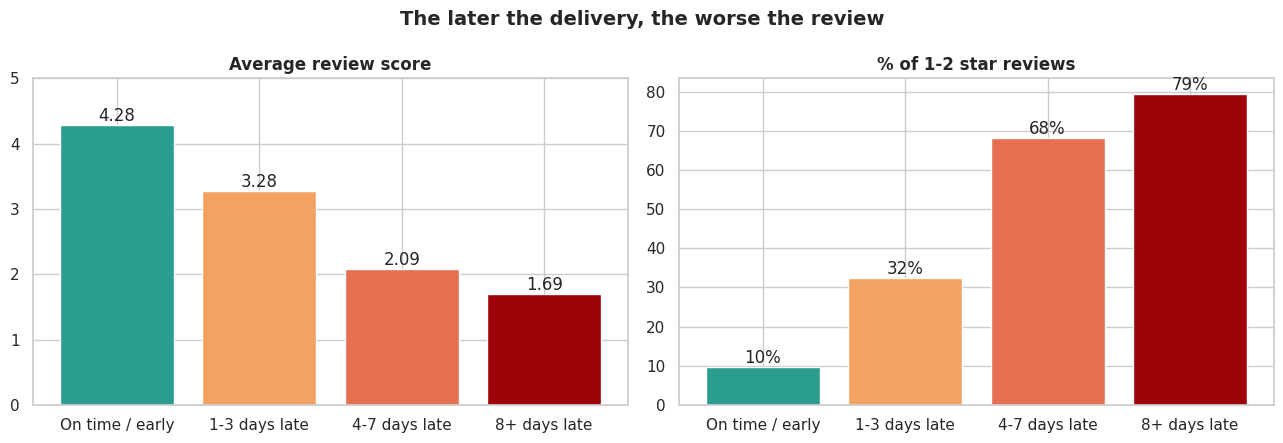

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
colors = [GREEN, "#f4a261", RED, "#9d0208"]

b1 = axes[0].bar(q2.index.astype(str), q2["avg_review"], color=colors)
axes[0].bar_label(b1, fmt="%.2f")
axes[0].set_title("Average review score")
axes[0].set_ylim(0, 5)

b2 = axes[1].bar(q2.index.astype(str), q2["bad_review_pct"], color=colors)
axes[1].bar_label(b2, fmt="%.0f%%")
axes[1].set_title("% of 1-2 star reviews")

fig.suptitle("The later the delivery, the worse the review", fontsize=14, weight="bold")
plt.tight_layout()
plt.show()

In [ ]:
bad_on_time = rated_delivered.loc[~rated_delivered["is_late"], "bad_review"].mean() * 100
bad_late    = rated_delivered.loc[rated_delivered["is_late"], "bad_review"].mean() * 100
late_times  = bad_late / bad_on_time

print(f"Bad-review rate - on time: {bad_on_time:.1f}% | late: {bad_late:.1f}%  -> {late_times:.1f}x higher when late")

summary["q2"] = (f"On-time orders get a bad review {bad_on_time:.0f}% of the time; late orders {bad_late:.0f}% "
                 f"of the time ({late_times:.1f}x more). The effect grows with the delay: "
                 f"{q2['avg_review'].iloc[0]:.2f} stars on time vs {q2['avg_review'].iloc[-1]:.2f} stars at 8+ days late.")
save_chart(fig, "2_delivery_vs_review", "Q2. Delivery timing vs. review score", summary["q2"])

Bad-review rate - on time: 9.5% | late: 62.9%  -> 6.6x higher when late


**Does it hold across regions and categories?** Compare on-time vs late review scores inside each region
and inside the 10 biggest categories.

In [ ]:
def on_time_vs_late(data, group_col):
    t = data.pivot_table(index=group_col, columns="is_late", values="review_score", aggfunc="mean")
    t = t.rename(columns={False: "On time", True: "Late"})
    t["Drop (stars)"] = t["On time"] - t["Late"]
    t["Late %"] = data.groupby(group_col)["is_late"].mean() * 100
    return t

region_q2 = on_time_vs_late(rated_delivered, "customer_region").sort_values("Late %")
region_q2

is_late,On time,Late,Drop (stars),Late %
customer_region,,,,
South,4.29,2.36,1.93,5.90
Southeast,4.29,2.28,2.01,6.12
Central-West,4.25,2.17,2.09,6.53
North,4.20,2.12,2.07,8.57
Northeast,4.22,2.15,2.06,12.72


In [ ]:
top10_categories = rated_delivered["category"].value_counts().head(10).index
category_q2 = on_time_vs_late(rated_delivered[rated_delivered["category"].isin(top10_categories)], "category")
category_q2.sort_values("Drop (stars)", ascending=False)

is_late,On time,Late,Drop (stars),Late %
category,,,,
toys,4.37,2.10,2.26,6.40
sports_leisure,4.37,2.15,2.21,6.59
watches_gifts,4.26,2.18,2.08,7.42
health_beauty,4.38,2.32,2.06,7.52
housewares,4.30,2.25,2.05,5.41
auto,4.29,2.29,2.00,7.34
computers_accessories,4.20,2.25,1.95,6.41
bed_bath_table,4.13,2.20,1.93,7.50
furniture_decor,4.20,2.34,1.86,7.21


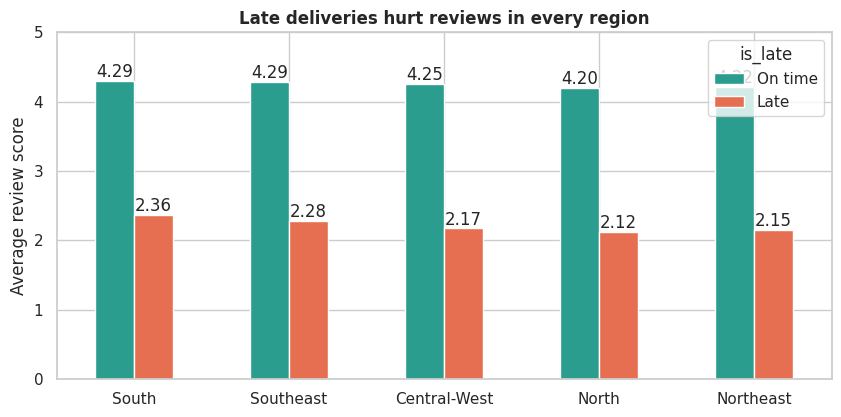

The pattern holds everywhere: late orders score lower in all 5 regions (drop of 1.9-2.1 stars) and in 10 of the top 10 categories. What differs is HOW OFTEN orders are late: 6% in South vs 13% in Northeast.


In [ ]:
fig, ax = plt.subplots(figsize=(10, 4.5))
region_q2[["On time", "Late"]].plot(kind="bar", ax=ax, color=[GREEN, RED], rot=0)
ax.set_title("Late deliveries hurt reviews in every region")
ax.set_ylabel("Average review score")
ax.set_xlabel("")
ax.set_ylim(0, 5)
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f")
plt.show()

n_cat_drop = (category_q2["Drop (stars)"] > 0).sum()
summary["q2b"] = (f"The pattern holds everywhere: late orders score lower in all {len(region_q2)} regions "
                  f"(drop of {region_q2['Drop (stars)'].min():.1f}-{region_q2['Drop (stars)'].max():.1f} stars) "
                  f"and in {n_cat_drop} of the top 10 categories. What differs is HOW OFTEN orders are late: "
                  f"{region_q2['Late %'].min():.0f}% in {region_q2.index[0]} vs "
                  f"{region_q2['Late %'].max():.0f}% in {region_q2.index[-1]}.")
print(summary["q2b"])
save_chart(fig, "3_late_by_region", "Q2. Late vs on-time reviews across regions", summary["q2b"])

**Answer (Q2):** Delivery timing is strongly linked to satisfaction — the later the parcel, the lower the score.
The drop happens in **every region and almost every category**, so it is a platform-wide problem.
What is concentrated is the *rate* of late deliveries, which is much higher in some regions (see Q3).

## 9. Q3 — Seller and geographic patterns

In [ ]:
seller_share   = sellers["seller_state"].value_counts(normalize=True).head(5) * 100
customer_share = customers["customer_state"].value_counts(normalize=True).head(5) * 100

pd.DataFrame({"% of sellers": seller_share, "% of customers": customer_share}).fillna(0)

,% of sellers,% of customers
MG,7.88,11.70
PR,11.28,5.07
RJ,5.53,12.92
RS,0.00,5.50
SC,6.14,0.00
SP,59.74,41.98


In [ ]:
region_q3 = delivered.groupby("customer_region").agg(
    orders          = ("order_id", "count"),
    avg_delivery_days = ("delivery_days", "mean"),
    avg_freight     = ("freight_value", "mean"),
    late_pct        = ("is_late", "mean"),
    avg_review      = ("review_score", "mean"),
)
region_q3["late_pct"] *= 100
region_q3["freight_%_of_value"] = (delivered.groupby("customer_region")["freight_value"].sum()
                                   / delivered.groupby("customer_region")["order_value"].sum() * 100)
region_q3.sort_values("avg_delivery_days")

,orders,avg_delivery_days,avg_freight,late_pct,avg_review,freight_%_of_value
customer_region,,,,,,
Southeast,66193,10.29,19.84,6.12,4.17,13.18
South,13813,13.56,24.35,5.90,4.18,15.03
Central-West,5624,14.56,26.49,6.53,4.12,14.96
Northeast,9044,19.54,35.99,12.72,3.95,17.86
North,1796,22.14,41.35,8.57,4.02,18.50


In [ ]:
same_state_q3 = delivered.groupby("same_state").agg(
    orders            = ("order_id", "count"),
    avg_delivery_days = ("delivery_days", "mean"),
    avg_freight       = ("freight_value", "mean"),
    late_pct          = ("is_late", "mean"),
    avg_review        = ("review_score", "mean"),
).rename(index={True: "Seller in same state", False: "Seller in another state"})
same_state_q3["late_pct"] *= 100
same_state_q3

,orders,avg_delivery_days,avg_freight,late_pct,avg_review
same_state,,,,,
Seller in another state,61765,14.68,26.91,8.05,4.08
Seller in same state,34705,7.48,15.45,4.50,4.25


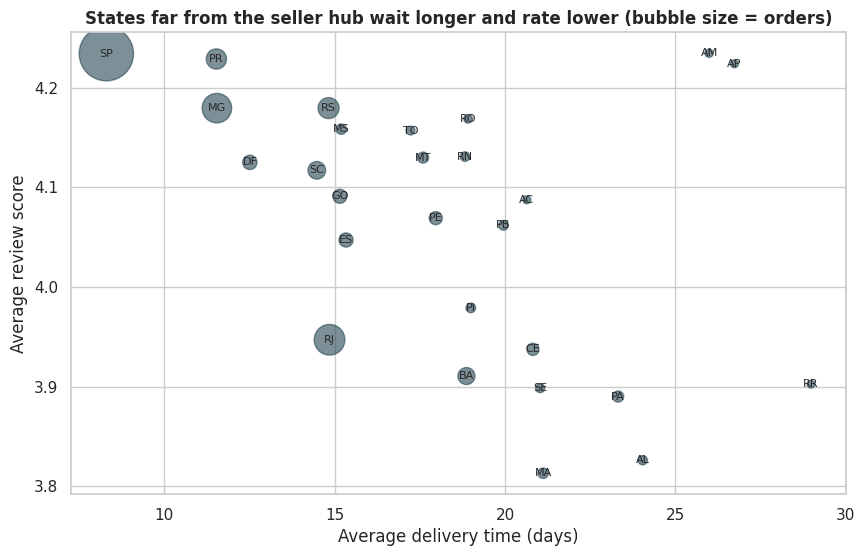

60% of sellers are in SP, so customers far from it wait longer: average delivery ranges from 10 days (Southeast) to 22 days (North). Same-state orders arrive in 7 days vs 15 days cross-state, with average freight of R$ 15 vs R$ 27. Across states, longer delivery goes with lower reviews (correlation -0.44).


In [ ]:
state_q3 = delivered.groupby("customer_state").agg(
    orders=("order_id", "count"),
    avg_delivery_days=("delivery_days", "mean"),
    avg_review=("review_score", "mean"),
)

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(state_q3["avg_delivery_days"], state_q3["avg_review"],
           s=state_q3["orders"] / state_q3["orders"].max() * 1500 + 30, alpha=0.6, color=BLUE)
for state, row in state_q3.iterrows():
    ax.annotate(state, (row["avg_delivery_days"], row["avg_review"]), ha="center", va="center", fontsize=8)
ax.set_xlabel("Average delivery time (days)")
ax.set_ylabel("Average review score")
ax.set_title("States far from the seller hub wait longer and rate lower (bubble size = orders)")
plt.show()

top_seller_state = seller_share.index[0]
corr_state = state_q3["avg_delivery_days"].corr(state_q3["avg_review"])
same, other = same_state_q3.loc["Seller in same state"], same_state_q3.loc["Seller in another state"]

summary["q3"] = (f"{seller_share.iloc[0]:.0f}% of sellers are in {top_seller_state}, so customers far from it wait longer: "
                 f"average delivery ranges from {region_q3['avg_delivery_days'].min():.0f} days "
                 f"({region_q3['avg_delivery_days'].idxmin()}) to {region_q3['avg_delivery_days'].max():.0f} days "
                 f"({region_q3['avg_delivery_days'].idxmax()}). Same-state orders arrive in {same['avg_delivery_days']:.0f} days "
                 f"vs {other['avg_delivery_days']:.0f} days cross-state, with average freight of "
                 f"R$ {same['avg_freight']:.0f} vs R$ {other['avg_freight']:.0f}. Across states, longer delivery goes with lower "
                 f"reviews (correlation {corr_state:+.2f}).")
print(summary["q3"])
save_chart(fig, "4_state_delivery_vs_review", "Q3. Geography: delivery time vs review by state", summary["q3"])

**Answer (Q3):** Sellers are heavily concentrated in the Southeast (mostly São Paulo). Customers in the North and
Northeast are far from them, so they **wait longer, pay more freight (as a share of order value), receive more late
orders and give lower reviews**. Geography mainly matters *through* delivery speed.

## 10. Q4 — Product category performance
Only categories with **at least 300 orders** are compared, so that small categories with a few odd reviews
don't distort the ranking.

In [ ]:
category = valid.groupby("category").agg(
    orders         = ("order_id", "count"),
    avg_price      = ("product_value", "mean"),
    avg_review     = ("review_score", "mean"),
    bad_review_pct = ("bad_review", "mean"),
)
category["bad_review_pct"] *= 100
category["late_pct"] = valid[valid["was_delivered"]].groupby("category")["is_late"].mean() * 100

platform_avg = valid["review_score"].mean()
big = category[category["orders"] >= 300].copy()
big["vs_platform_avg"] = big["avg_review"] - platform_avg

print(f"Platform average review: {platform_avg:.2f}  |  categories compared: {len(big)}\n")
print("Top 10 categories by number of orders:")
big.sort_values("orders", ascending=False).head(10)

Platform average review: 4.10  |  categories compared: 32

Top 10 categories by number of orders:


,orders,avg_price,avg_review,bad_review_pct,late_pct,vs_platform_avg
category,,,,,,
bed_bath_table,9281,111.08,3.96,16.98,7.50,-0.14
health_beauty,8767,143.37,4.18,12.73,7.52,0.08
sports_leisure,7638,128.24,4.17,12.83,6.59,0.07
computers_accessories,6626,136.59,4.03,16.01,6.41,-0.07
furniture_decor,6327,115.34,4.02,16.34,7.21,-0.08
housewares,5792,108.72,4.15,12.95,5.41,0.05
watches_gifts,5583,214.27,4.06,15.24,7.42,-0.04
telephony,4165,77.29,4.00,15.46,7.14,-0.10
auto,3852,152.09,4.10,14.23,7.34,-0.00


In [ ]:
worst5 = big.nsmallest(5, "avg_review")
best5  = big.nlargest(5, "avg_review")
print("Weakest categories:"); display(worst5)
print("Strongest categories:"); display(best5)

Weakest categories:


,orders,avg_price,avg_review,bad_review_pct,late_pct,vs_platform_avg
category,,,,,,
office_furniture,1263,215.99,3.62,22.64,8.11,-0.48
audio,347,149.58,3.83,21.90,11.85,-0.27
home_confort,373,155.48,3.92,18.23,9.51,-0.18
unknown,1399,126.48,3.95,19.09,7.08,-0.16
bed_bath_table,9281,111.08,3.96,16.98,7.50,-0.14


Strongest categories:


,orders,avg_price,avg_review,bad_review_pct,late_pct,vs_platform_avg
category,,,,,,
books_general_interest,502,90.91,4.50,7.17,6.50,0.40
luggage_accessories,1024,136.79,4.34,8.79,4.34,0.24
food,444,65.59,4.26,12.16,7.11,0.16
stationery,2287,100.89,4.25,11.28,6.57,0.15
pet_shop,1699,125.91,4.24,11.42,5.12,0.14


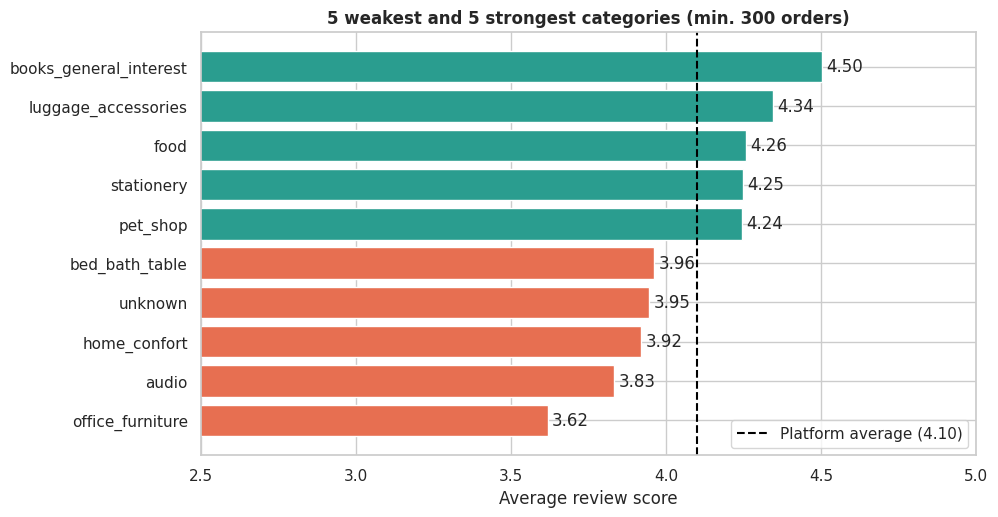

Weakest: office_furniture, audio, home_confort (3.62-3.92 stars). Strongest: books_general_interest, luggage_accessories, food (up to 4.50). Late-delivery rate: 8.8% in the weakest vs 5.9% in the strongest. Correlation between category price and review score: -0.20 (weak link).


In [ ]:
plot_cat = pd.concat([worst5, best5]).sort_values("avg_review")

fig, ax = plt.subplots(figsize=(10, 5.5))
colors = [RED if v < platform_avg else GREEN for v in plot_cat["avg_review"]]
bars = ax.barh(plot_cat.index, plot_cat["avg_review"], color=colors)
ax.bar_label(bars, fmt="%.2f", padding=3)
ax.axvline(platform_avg, color="black", linestyle="--", label=f"Platform average ({platform_avg:.2f})")
ax.set_xlim(2.5, 5)
ax.set_xlabel("Average review score")
ax.set_title("5 weakest and 5 strongest categories (min. 300 orders)")
ax.legend(loc="lower right")
plt.show()

corr_price = big["avg_price"].corr(big["avg_review"])
summary["q4"] = (f"Weakest: {', '.join(worst5.index[:3])} ({worst5['avg_review'].min():.2f}-{worst5['avg_review'].iloc[2]:.2f} stars). "
                 f"Strongest: {', '.join(best5.index[:3])} (up to {best5['avg_review'].max():.2f}). "
                 f"Late-delivery rate: {worst5['late_pct'].mean():.1f}% in the weakest vs "
                 f"{best5['late_pct'].mean():.1f}% in the strongest. Correlation between category price and "
                 f"review score: {corr_price:+.2f} ({'weak' if abs(corr_price) < 0.3 else 'moderate/strong'} link).")
print(summary["q4"])
save_chart(fig, "5_category_reviews", "Q4. Strongest and weakest product categories", summary["q4"])

**Answer (Q4):** Volume is concentrated in a handful of categories (bed/bath, health & beauty, sports, furniture…).
Most categories sit close to the platform average; the weak ones combine **more late deliveries** with product/listing
or listing issues (check where the `unknown` category — products with incomplete listings — ranks in the table). Expensive categories are not
rated better or worse.

## 11. Q5 — Payment behaviour

In [ ]:
pay = valid[valid["payment_type"].notna() & (valid["payment_type"] != "not_defined")]

payment_q5 = pay.groupby("payment_type").agg(
    orders          = ("order_id", "count"),
    avg_order_value = ("payment_value", "mean"),
    avg_installments= ("installments", "mean"),
    avg_review      = ("review_score", "mean"),
    bad_review_pct  = ("bad_review", "mean"),
).sort_values("orders", ascending=False)
payment_q5["bad_review_pct"] *= 100
payment_q5.insert(1, "share_%", payment_q5["orders"] / payment_q5["orders"].sum() * 100)
payment_q5

,orders,share_%,avg_order_value,avg_installments,avg_review,bad_review_pct
payment_type,,,,,,
credit_card,75617,77.00,165.81,3.51,4.10,14.31
boleto,19539,19.90,144.67,1.00,4.10,14.03
voucher,1535,1.56,105.23,1.00,4.03,16.42
debit_card,1515,1.54,140.28,1.00,4.18,12.74


In [ ]:
card = pay[pay["payment_type"] == "credit_card"].copy()
card["installment_group"] = pd.cut(card["installments"], bins=[-1, 1, 3, 6, 10, 100],
                                   labels=["1 (full)", "2-3", "4-6", "7-10", "11+"])

installments_q5 = card.groupby("installment_group", observed=True).agg(
    orders          = ("order_id", "count"),
    avg_order_value = ("payment_value", "mean"),
    avg_review      = ("review_score", "mean"),
    late_pct        = ("is_late", "mean"),
)
installments_q5["late_pct"] *= 100
installments_q5

,orders,avg_order_value,avg_review,late_pct
installment_group,,,,
1 (full),25029,101.30,4.17,5.89
2-3,22548,135.68,4.10,6.71
4-6,16022,182.23,4.07,6.83
7-10,11682,334.04,4.01,7.30
11+,336,362.25,3.87,8.04


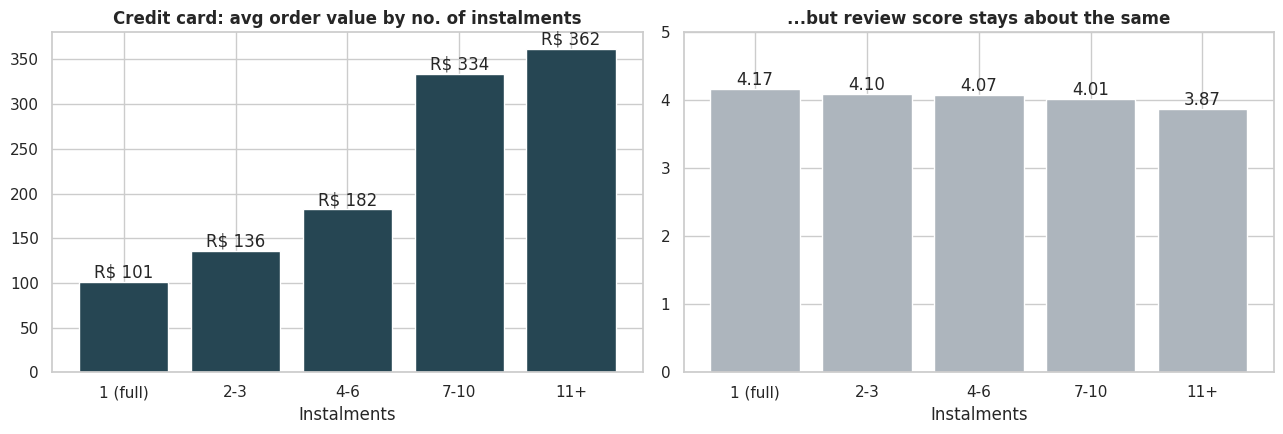

Credit Card is used for 77% of orders. More instalments go with bigger orders: R$ 101 when paid in full vs R$ 362 at 11+ instalments (correlation +0.37). Review scores barely change across payment types (4.03-4.18) - payment explains spend, not satisfaction.


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

b1 = axes[0].bar(installments_q5.index.astype(str), installments_q5["avg_order_value"], color=BLUE)
axes[0].bar_label(b1, fmt="R$ %.0f")
axes[0].set_title("Credit card: avg order value by no. of instalments")
axes[0].set_xlabel("Instalments")

b2 = axes[1].bar(installments_q5.index.astype(str), installments_q5["avg_review"], color=GREY)
axes[1].bar_label(b2, fmt="%.2f")
axes[1].set_ylim(0, 5)
axes[1].set_title("...but review score stays about the same")
axes[1].set_xlabel("Instalments")
plt.tight_layout()
plt.show()

corr_inst = card["installments"].corr(card["payment_value"])
top_type  = payment_q5.index[0]
summary["q5"] = (f"{top_type.replace('_', ' ').title()} is used for {payment_q5.loc[top_type, 'share_%']:.0f}% of orders. "
                 f"More instalments go with bigger orders: R$ {installments_q5['avg_order_value'].iloc[0]:.0f} when paid in full vs "
                 f"R$ {installments_q5['avg_order_value'].iloc[-1]:.0f} at 11+ instalments (correlation {corr_inst:+.2f}). "
                 f"Review scores barely change across payment types ({payment_q5['avg_review'].min():.2f}-"
                 f"{payment_q5['avg_review'].max():.2f}) - payment explains spend, not satisfaction.")
print(summary["q5"])
save_chart(fig, "6_payments", "Q5. Payment behaviour", summary["q5"])

**Answer (Q5):** Credit card dominates, followed by *boleto* (a Brazilian bank slip). Customers use instalments to
afford **more expensive orders**, so instalments are a strong signal of order value. Payment method has almost
**no link to satisfaction** — it is not a lever for improving reviews.

## 12. Q6 — Root cause: what is behind low reviews?
**Method (simple comparison):** for each possible factor, compare the bad-review rate of orders **with** the factor
against orders **without** it. "Times more likely" = rate with ÷ rate without.

- **≥ 2x → primary driver** (strong link)
- **1.25x – 2x → secondary / contributing**
- **< 1.25x → weak or no link**

In [ ]:
rated = df[df["review_score"].notna()].copy()
rated_del = rated[rated["was_delivered"]]
on_time = rated_del[~rated_del["is_late"]]

def compare(factor, data, has_factor):
    # Compare bad-review % for orders with vs without a factor.
    with_f    = data.loc[has_factor, "bad_review"].mean() * 100
    without_f = data.loc[~has_factor, "bad_review"].mean() * 100
    return {"Factor": factor,
            "% of orders affected": has_factor.mean() * 100,
            "Bad review % (with)": with_f,
            "Bad review % (without)": without_f,
            "Times more likely": with_f / without_f}

rows = [
    compare("Order never delivered",               rated,     ~rated["was_delivered"]),
    compare("Delivered late",                      rated_del, rated_del["is_late"]),
    compare("On time but slow (over 20 days)",     on_time,   on_time["delivery_days"] > 20),
    compare("Order has items from 2+ sellers",     rated,     rated["n_sellers"] > 1),
    compare("Order has 2+ items",                  rated,     rated["n_items"] > 1),
    compare("Product has missing category info",   rated,     rated["category"] == "unknown"),
    compare("Seller in a different state",         rated_del, ~rated_del["same_state"]),
    compare("Freight is over 25% of order value",  rated,     rated["freight_value"] / rated["order_value"] > 0.25),
    compare("Paid with boleto",                    rated,     rated["payment_type"] == "boleto"),
    compare("Paid in 6+ instalments",              rated,     rated["installments"] >= 6),
]
drivers = pd.DataFrame(rows).set_index("Factor").sort_values("Times more likely", ascending=False)
drivers["Level"] = pd.cut(drivers["Times more likely"], bins=[0, 1.25, 2, 100],
                          labels=["Weak / none", "Secondary", "Primary"])
drivers

,% of orders affected,Bad review % (with),Bad review % (without),Times more likely,Level
Factor,,,,,
Delivered late,6.77,62.87,9.54,6.59,Primary
Order never delivered,2.99,78.02,13.16,5.93,Primary
Order has items from 2+ sellers,1.29,47.81,14.67,3.26,Primary
Order has 2+ items,9.86,28.27,13.65,2.07,Primary
On time but slow (over 20 days),7.65,15.78,9.03,1.75,Secondary
Seller in a different state,64.03,14.47,10.81,1.34,Secondary
Product has missing category info,1.42,19.67,15.03,1.31,Secondary
Paid in 6+ instalments,16.17,17.39,14.65,1.19,Weak / none
Freight is over 25% of order value,30.07,15.11,15.09,1.00,Weak / none


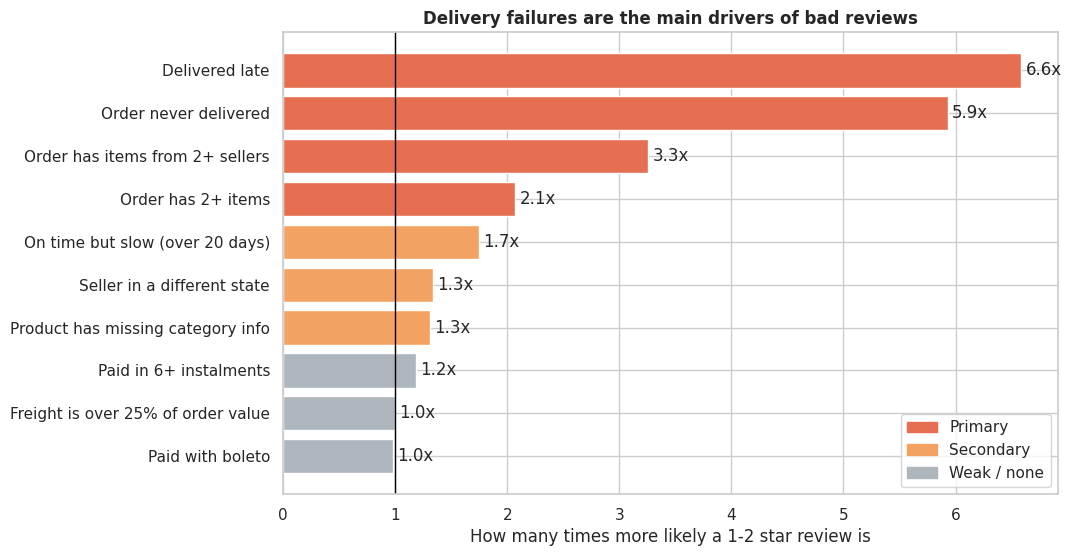

Primary drivers (2x+ more bad reviews): Delivered late, Order never delivered, Order has items from 2+ sellers, Order has 2+ items. Secondary: On time but slow (over 20 days), Seller in a different state, Product has missing category info. Weak or no link: Paid in 6+ instalments, Freight is over 25% of order value, Paid with boleto.


In [ ]:
level_colors = {"Primary": RED, "Secondary": "#f4a261", "Weak / none": GREY}
plot_d = drivers.sort_values("Times more likely")

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(plot_d.index, plot_d["Times more likely"], color=plot_d["Level"].astype(str).map(level_colors))
ax.bar_label(bars, fmt="%.1fx", padding=3)
ax.axvline(1, color="black", linewidth=1)
ax.set_xlabel("How many times more likely a 1-2 star review is")
ax.set_title("Delivery failures are the main drivers of bad reviews")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in level_colors.values()]
ax.legend(handles, level_colors.keys(), loc="lower right")
plt.show()

primary = drivers[drivers["Level"] == "Primary"].index.tolist()
secondary = drivers[drivers["Level"] == "Secondary"].index.tolist()
weak = drivers[drivers["Level"] == "Weak / none"].index.tolist()
summary["q6a"] = (f"Primary drivers (2x+ more bad reviews): {', '.join(primary) or 'none'}. "
                  f"Secondary: {', '.join(secondary) or 'none'}. "
                  f"Weak or no link: {', '.join(weak) or 'none'}.")
print(summary["q6a"])
save_chart(fig, "7_root_cause_factors", "Q6. Which factors are linked to bad reviews?", summary["q6a"])

**How much of the problem does each driver explain?** A factor can be strong but rare. So we take every bad review
and assign it to **one** reason, checking the reasons in order of strength.

In [ ]:
bad = rated[rated["bad_review"] == 1]

reasons = np.select(
    [~bad["was_delivered"],
     bad["is_late"],
     bad["delivery_days"] > 20,
     bad["n_sellers"] > 1],
    ["Never delivered",
     "Delivered late",
     "On time but slow (20+ days)",
     "Multi-seller order"],
    default="On time & fast (product / seller issue)")

reason_share = pd.Series(reasons).value_counts(normalize=True) * 100
reason_share

,proportion
On time & fast (product / seller issue),46.13
Delivered late,27.37
Never delivered,15.44
On time but slow (20+ days),7.23
Multi-seller order,3.83


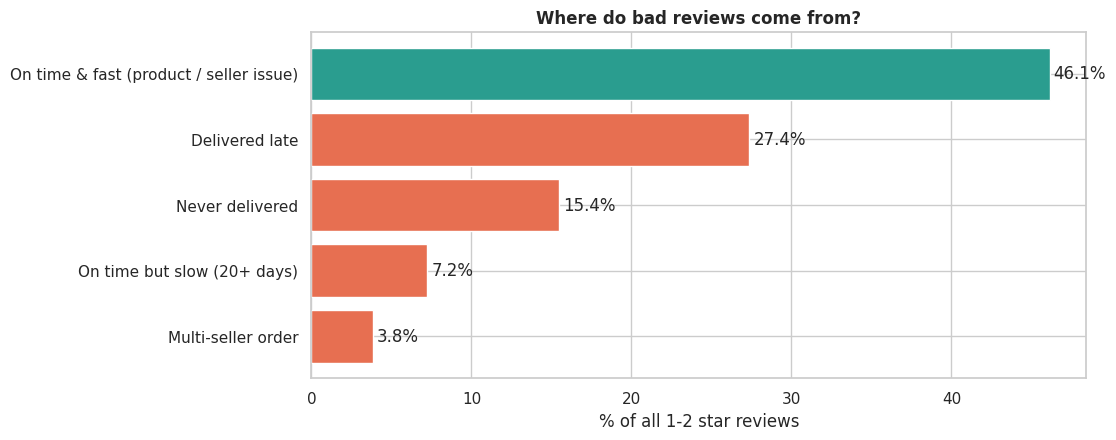

54% of all bad reviews come from orders with a delivery problem (never delivered, late, very slow or split across sellers). The remaining 46% were delivered on time and fast, pointing to product quality, wrong item or listing issues.


In [ ]:
fig, ax = plt.subplots(figsize=(10, 4.5))
rs = reason_share.sort_values()
bars = ax.barh(rs.index, rs.values,
               color=[GREEN if "product" in i else RED for i in rs.index])
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.set_xlabel("% of all 1-2 star reviews")
ax.set_title("Where do bad reviews come from?")
plt.show()

delivery_share = 100 - reason_share.get("On time & fast (product / seller issue)", 0)
summary["q6b"] = (f"{delivery_share:.0f}% of all bad reviews come from orders with a delivery problem "
                  f"(never delivered, late, very slow or split across sellers). The remaining "
                  f"{100 - delivery_share:.0f}% were delivered on time and fast, pointing to product quality, "
                  f"wrong item or listing issues.")
print(summary["q6b"])
save_chart(fig, "8_bad_review_breakdown", "Q6. Breakdown of all bad reviews by likely reason", summary["q6b"])

**Answer (Q6):**
- **Primary drivers** — the order *never arriving* and *arriving late*. They have the strongest link to bad reviews and
  explain a large share of them.
- **Secondary drivers** — orders split across several sellers / items (they often arrive in pieces), very slow deliveries,
  and incomplete product listings.
- **Weak / no link** — payment method and instalments.
- The rest of the bad reviews happen on orders that arrived on time, which points to **product quality or listing accuracy**.

> These are *associations* found in historical data, not proven causes — but the pattern is consistent across
> time (Q1), regions and categories (Q2), and geography (Q3), which makes delivery the most likely main driver.

## 13. Key findings & recommendations

In [ ]:
findings = [summary[k] for k in ["q1", "q2", "q2b", "q3", "q4", "q5", "q6a", "q6b"]]

recommendations = [
    f"Fix late deliveries first: late orders are {late_times:.1f}x more likely to get a bad review. "
    f"Track on-time rate per seller and per region as a core KPI.",
    "Chase orders that are never delivered - these are the most damaging orders of all. "
    "Proactively contact customers when a parcel is stuck.",
    f"Set realistic delivery estimates for far-away regions "
    f"({' / '.join(dict.fromkeys([region_q3['avg_delivery_days'].idxmax(), region_q3['late_pct'].idxmax()]))}): "
    f"a later but kept promise is better than a broken one.",
    "Grow sellers outside the São Paulo hub (or use regional warehouses) to cut distance, freight and delay.",
    "Improve listings with missing category/details, and review sellers in the weakest categories for product quality.",
    "Use instalments as a sales lever for high-value items - it drives order size, not dissatisfaction.",
]

print("KEY FINDINGS"); print("=" * 80)
for i, f in enumerate(findings, 1):
    print(textwrap.fill(f"{i}. {f}", 100, subsequent_indent="   ")); print()
print("RECOMMENDATIONS"); print("=" * 80)
for i, r in enumerate(recommendations, 1):
    print(textwrap.fill(f"{i}. {r}", 100, subsequent_indent="   ")); print()

KEY FINDINGS
1. Orders grew 8.2x and revenue 7.3x from Jan 2017 to Aug 2018, while average order value moved only
   -10.8% - growth came from more orders, not bigger baskets. Review scores moved with the late-
   delivery rate (correlation -0.87) much more than with order volume (correlation -0.19).

2. On-time orders get a bad review 10% of the time; late orders 63% of the time (6.6x more). The
   effect grows with the delay: 4.28 stars on time vs 1.69 stars at 8+ days late.

3. The pattern holds everywhere: late orders score lower in all 5 regions (drop of 1.9-2.1 stars)
   and in 10 of the top 10 categories. What differs is HOW OFTEN orders are late: 6% in South vs 13%
   in Northeast.

4. 60% of sellers are in SP, so customers far from it wait longer: average delivery ranges from 10
   days (Southeast) to 22 days (North). Same-state orders arrive in 7 days vs 15 days cross-state,
   with average freight of R$ 15 vs R$ 27. Across states, longer delivery goes with lower reviews
   (

## 14. Export the PDF report
Creates a PDF with a summary page (KPIs, key findings, recommendations) followed by the charts (two per page) with captions,
and saves it (plus every chart as PNG) to the `report` folder in Google Drive.

In [ ]:
from matplotlib.backends.backend_pdf import PdfPages

PDF_PATH = os.path.join(REPORT_DIR, "Olist_Analysis_Report.pdf")
A4 = (8.27, 11.69)

def safe(text):
    # matplotlib treats text between two "$" signs as a math formula -> escape them
    return text.replace("$", r"\$")

def new_page(title=None):
    fig = plt.figure(figsize=A4)
    y = 0.95
    if title:
        fig.text(0.07, y, title, fontsize=18, weight="bold", color=BLUE)
        y -= 0.045
    return fig, y

def write_bullets(pdf, fig, y, heading, bullets, width=92):
    # Write a heading + wrapped bullet points; start a new page if we run out of space.
    if y < 0.2:
        pdf.savefig(fig); plt.close(fig)
        fig, y = new_page()
    fig.text(0.07, y, heading, fontsize=13, weight="bold", color=BLUE)
    y -= 0.03
    for i, text in enumerate(bullets, 1):
        lines = textwrap.wrap(text, width)
        if y - 0.018 * len(lines) < 0.05:
            pdf.savefig(fig); plt.close(fig)
            fig, y = new_page()
        for j, line in enumerate(lines):
            fig.text(0.07 if j == 0 else 0.095, y, safe((f"{i}. " if j == 0 else "") + line), fontsize=9.5)
            y -= 0.018
        y -= 0.008
    return fig, y - 0.015

with PdfPages(PDF_PATH) as pdf:
    # ---- Page 1: title, KPIs, findings, recommendations ----
    fig, y = new_page("Olist E-Commerce Analysis")
    fig.text(0.07, y, "What drives customer satisfaction on a Brazilian marketplace  |  ~100k orders, 2016-2018",
             fontsize=10, color="dimgray")
    y -= 0.05

    kpis = ["Total orders", "Total revenue", "Avg order value", "Avg review score",
            "Bad reviews (1-2 star)", "Late deliveries", "Avg delivery time", "Unique customers"]
    for i, k in enumerate(kpis):
        x = 0.07 + (i % 4) * 0.225
        yy = y - (i // 4) * 0.075
        fig.text(x, yy, safe(summary[k]), fontsize=14, weight="bold", color=BLUE,
                 bbox=dict(boxstyle="round,pad=0.6", fc="#eef3f7", ec="#c9d6e0"))
        fig.text(x, yy - 0.028, k, fontsize=8.5, color="dimgray")
    y -= 0.19

    fig, y = write_bullets(pdf, fig, y, "Key findings", findings)
    fig, y = write_bullets(pdf, fig, y, "Recommendations", recommendations)
    pdf.savefig(fig); plt.close(fig)

    # ---- Charts: two per page ----
    for i, chart in enumerate(report_charts):
        if i % 2 == 0:
            fig = plt.figure(figsize=A4)
        top = 0.95 if i % 2 == 0 else 0.48
        fig.text(0.07, top, safe(chart["title"]), fontsize=13, weight="bold", color=BLUE)
        ax = fig.add_axes([0.07, top - 0.33, 0.86, 0.31])
        ax.imshow(plt.imread(chart["path"]))
        ax.axis("off")
        for k, line in enumerate(textwrap.wrap(chart["caption"], 100)):
            fig.text(0.07, top - 0.36 - k * 0.017, safe(line), fontsize=9)
        if i % 2 == 1 or i == len(report_charts) - 1:
            pdf.savefig(fig); plt.close(fig)

print("Report saved to:", PDF_PATH)

# Offer a direct download when running in Colab
try:
    from google.colab import files
    files.download(PDF_PATH)
except ImportError:
    pass

Report saved to: /content/drive/MyDrive/OLIST/report/Olist_Analysis_Report.pdf


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
### Limitations
- The data shows **associations**, not proven cause and effect.
- For orders with several items, the category and seller state of the **first item** are used.
- Geography is analysed at state/region level; exact distances (from the geolocation table) could refine Q3.